# Week 6 · Class 2 — Linear regression and regularisation, from start to finish 🐟

**2 hours** · we code together · one dataset for the whole session: `Fish.csv`

**The project:** a fish market wants to estimate the **weight** of a fish from measurements that are quick to take (length, height, width) and its species. Weight is a number, so this is a **regression** problem.

| Part | Time | What we do | Why |
|---|---|---|---|
| 0 | 3' | Setup and load the data | |
| 1 | 6' | First look and cleaning | know the data before modelling |
| 2 | 7' | EDA: one variable at a time | shape, skew, outliers |
| 3 | 4' | EDA: the species | does the category matter? |
| 4 | 10' | **Confidence intervals** | how sure are we about an average? |
| 5 | 6' | EDA: relationships | which features move with the weight? |
| 6 | 10' | **Model, iteration 1** (step by step) | a first baseline |
| 7 | 12' | **Log transform** | fix what the baseline gets wrong |
| 8 | 4' | The statistics of the model | confidence intervals for the coefficients |
| 9 | 8' | **Model, iteration 2: the `Pipeline`** | same model, clean and safe code |
| | | ☕ *first half done: 70 minutes* | |
| 10 | 7' | Correlated features: unstable coefficients | the problem regularisation solves |
| 11 | 10' | Polynomial features: more power… and **overfitting** | another way to fit a curve |
| 12 | 10' | **Ridge and Lasso** | keep the power, remove the danger |
| 13 | 10' | The effect of alpha and `GridSearchCV` | choosing the strength of the penalty |
| 14 | 3' | Recap | |

Total: about 110 minutes. If time is short, parts 8 and the two alpha plots of part 13 can be read at home.

🧑‍💻 = we write the code together. 📖 = how to read the result.

---
## 0 · Setup and load the data (3')

**In Google Colab:** click the folder icon on the left and drag `Fish.csv` into it. Or run the next cell without the `#` signs and choose the file.

In [1]:
## Colab only: remove the two # below, run the cell and choose Fish.csv
# from google.colab import files
# files.upload()

In [1]:
## import dependencies

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
df = pd.read_csv("../data/Fish.csv")
df

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672


**The columns**
- `Species`: the kind of fish (text)
- `Weight`: weight in grams → **our target**
- `Length1`, `Length2`, `Length3`: three ways of measuring the length, in cm
- `Height`, `Width`: in cm

---
## 1 · First look and cleaning (6')

Three questions before anything else: **how big** is the data, **what type** is each column, and **is anything missing or strange**?

🧑‍💻 Size, types and missing values.

In [4]:
df.shape

(159, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 8.8 KB


In [6]:
df.isna().sum()

Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

In [7]:
## duplicated rows
df.duplicated().sum()

np.int64(0)

🧑‍💻 Descriptive statistics. Look at the **min** of each column.

In [8]:
df.describe()

,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


📖 The minimum `Weight` is **0 grams**. A fish cannot weigh nothing: this is a **data error**, not a real fish.

A missing value is not always written as `NaN`. Sometimes it hides as an impossible number, and only `describe()` shows it.

In [9]:
## which rows have an impossible weight?
df[df["Weight"] <= 0]

,Species,Weight,Length1,Length2,Length3,Height,Width
40,Roach,0.0,19.0,20.5,22.8,6.4752,3.3516


In [10]:
## we keep only the fish with a real weight
df = df[df["Weight"] > 0]
df.shape

(158, 7)

📖 We removed 1 row out of 159. We could not repair it (we do not know the real weight), and one row is a small price.

---
## 2 · EDA: one variable at a time (7')

We start with the **target**. Its shape tells us what kind of model problems to expect.

🧑‍💻 Histogram of the weight.

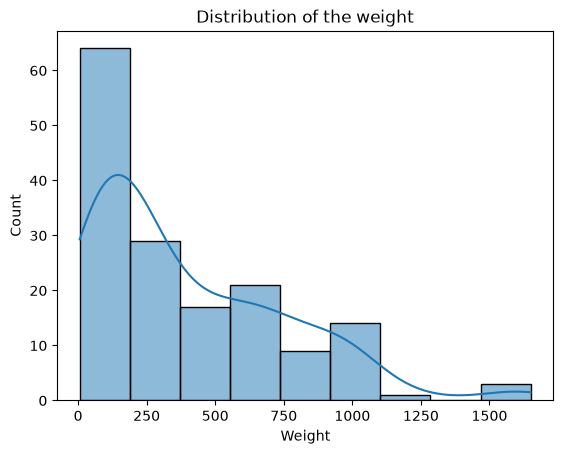

In [11]:
sns.histplot(df["Weight"], kde=True)
plt.title("Distribution of the weight")
plt.show()

In [12]:
## skewness: 0 = symmetric, positive = long tail on the right
df["Weight"].skew()

np.float64(1.1016850135015805)

📖 The weight is **right-skewed**: many light fish, a few very heavy ones (skewness around 1.1).

Why we care: a straight-line model is pulled by the few heavy fish. Keep this in mind, we come back to it in part 7.

🧑‍💻 Now all the numeric columns at once.

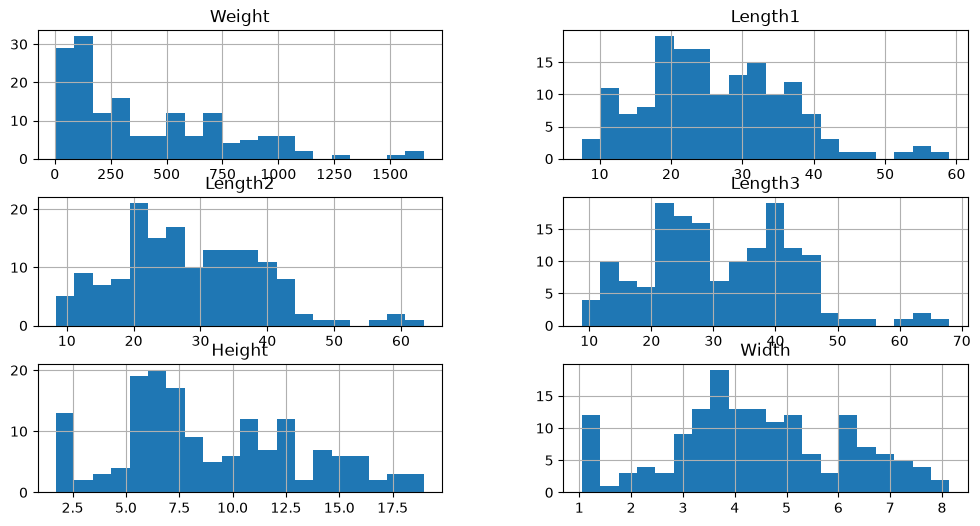

In [13]:
numeric_columns = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]

df[numeric_columns].hist(figsize=(12, 6), bins=20)
plt.show()

🧑‍💻 Outliers: a boxplot of the weight.

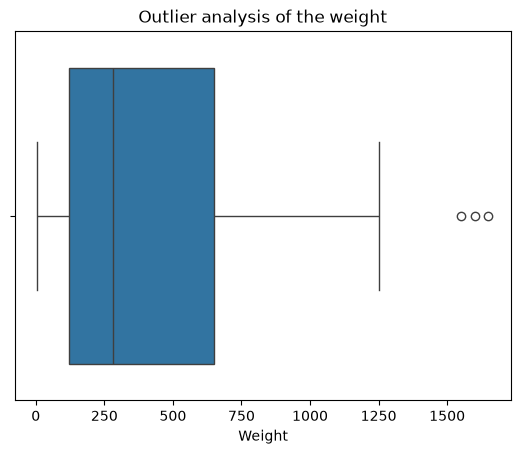

In [14]:
sns.boxplot(x=df["Weight"])
plt.title("Outlier analysis of the weight")
plt.show()

In [15]:
## the boxplot rule: a point is an outlier if it is above Q3 + 1.5 * IQR
Q1 = df["Weight"].quantile(0.25)
Q3 = df["Weight"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

df[df["Weight"] > upper_limit]

,Species,Weight,Length1,Length2,Length3,Height,Width
142,Pike,1600.0,56.0,60.0,64.0,9.600,6.144
143,Pike,1550.0,56.0,60.0,64.0,9.600,6.144
144,Pike,1650.0,59.0,63.4,68.0,10.812,7.480


📖 The three "outliers" are all **Pike**, a species that really grows that big. They are **real fish**, not errors.

**Rule:** remove a value when it is *wrong* (the 0 g fish). Keep a value when it is *rare but real* (the big pikes). If we deleted them, our model would never learn to weigh a big pike.

---
## 3 · EDA: the species (4')

🧑‍💻 How many fish of each species?

In [16]:
df["Species"].value_counts()

Species
Perch        56
Bream        35
Roach        19
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

🧑‍💻 Does the weight change with the species?

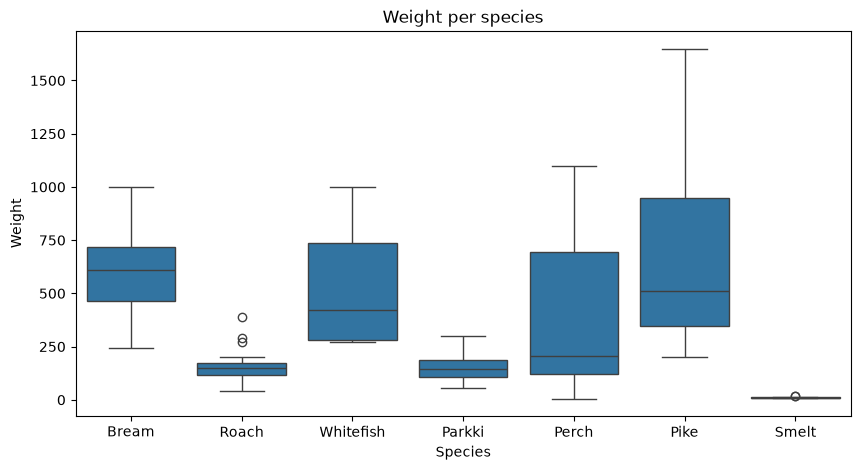

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Species", y="Weight")
plt.title("Weight per species")
plt.show()

📖 Yes: Smelt are tiny, Pike and Bream are heavy. The species carries information, so it will be a **feature** of our model.

Also notice: some species have very few fish (Whitefish: 6). Remember this for the next part.

---
## 4 · Confidence intervals (10')

### Why do we need them?
We measured **35 Bream**. The market wants to know the average weight of **all** the Bream in the lake. Our 35 fish are only a **sample**: another catch would give a slightly different average.

A **confidence interval** answers: *"given my sample, in which range is the true average likely to be?"*

It is built from three ingredients:

$$\text{mean} \;\pm\; t \times \frac{\text{std}}{\sqrt{n}}$$

- **mean**: our best guess
- **std / √n**: the **standard error**, how much the mean would move from one sample to another. More fish (bigger n) → smaller error.
- **t**: how many standard errors we take to be 95% confident (about 2)

🧑‍💻 Step by step, for the Bream.

In [18]:
bream = df[df["Species"] == "Bream"]["Weight"]

n = len(bream)
mean = bream.mean()
std = bream.std()

print("number of fish:", n)
print("mean weight:", mean)
print("standard deviation:", std)

number of fish: 35
mean weight: 617.8285714285714
standard deviation: 209.20570874483462


In [19]:
## standard error: how much the mean moves from sample to sample
standard_error = std / np.sqrt(n)
standard_error

np.float64(35.36221897183836)

In [20]:
## t value for 95% confidence (close to 2)
t_value = stats.t.ppf(0.975, df=n - 1)
t_value

np.float64(2.0322445093177186)

In [21]:
lower = mean - t_value * standard_error
upper = mean + t_value * standard_error

print("95% confidence interval for the mean weight of Bream:")
print(lower, "to", upper)

95% confidence interval for the mean weight of Bream:
545.963896085762 to 689.6932467713808


📖 **How to say it:** "We are 95% confident that the average weight of all Bream is between about 546 g and 690 g."

It is a statement about the **average**, not about one fish. A single Bream can weigh 250 g or 1000 g.

🧑‍💻 The same result in one line with `scipy`.

In [22]:
stats.t.interval(0.95, df=n - 1, loc=mean, scale=standard_error)

(np.float64(545.963896085762), np.float64(689.6932467713808))

🧑‍💻 Now for every species, with a loop.

In [23]:
for species in df["Species"].unique():
    weights = df[df["Species"] == species]["Weight"]
    n = len(weights)
    interval = stats.t.interval(0.95, df=n - 1, loc=weights.mean(), scale=stats.sem(weights))
    print(species, "| fish:", n, "| mean:", round(weights.mean()), "| interval:", round(interval[0]), "to", round(interval[1]))

Bream | fish: 35 | mean: 618 | interval: 546 to 690
Roach | fish: 19 | mean: 160 | interval: 120 to 200
Whitefish | fish: 6 | mean: 531 | interval: 206 to 856
Parkki | fish: 11 | mean: 155 | interval: 102 to 208
Perch | fish: 56 | mean: 382 | interval: 289 to 475
Pike | fish: 17 | mean: 719 | interval: 465 to 973
Smelt | fish: 14 | mean: 11 | interval: 9 to 14


🧑‍💻 `seaborn` draws these intervals for us: the black lines on a barplot **are** 95% confidence intervals.

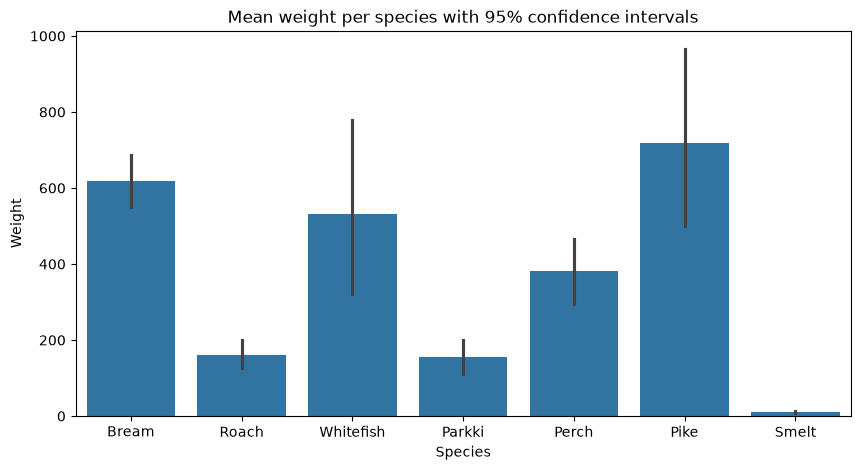

In [24]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Species", y="Weight", errorbar=("ci", 95))
plt.title("Mean weight per species with 95% confidence intervals")
plt.show()

📖 **Reading the intervals**
- **Whitefish** has a huge interval (about 200 g to 850 g): only 6 fish, so we know very little about its true average.
- **Smelt** has a tiny interval: the fish are all alike, so 14 fish are enough.
- **Bream vs Roach**: the intervals do not overlap → the averages are really different.
- **Bream vs Pike**: the intervals overlap → with this data we cannot say which species is heavier on average.

**Why this matters for modelling:** an average without its interval hides how much data is behind it. In part 8 we use the same idea for the **coefficients** of the model.

---
## 5 · EDA: relationships between the variables (6')

🧑‍💻 Weight against length, one colour per species.

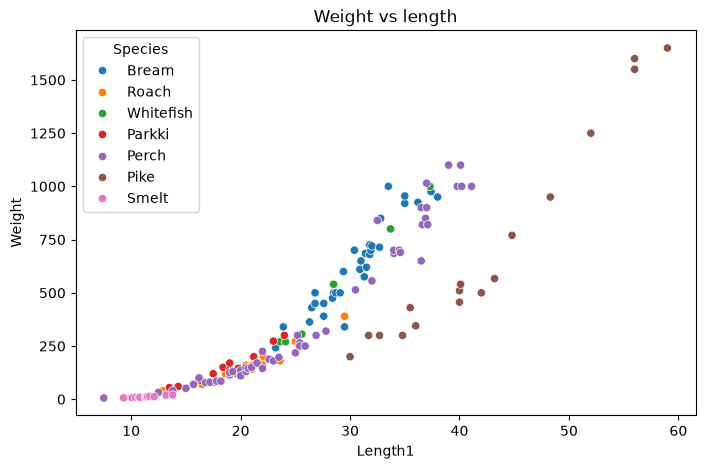

In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Length1", y="Weight", hue="Species")
plt.title("Weight vs length")
plt.show()

📖 Two things to see:
1. The longer the fish, the heavier: a strong relationship.
2. The cloud is **curved**, like a banana. A straight line will not follow it well. Remember this for part 7.

🧑‍💻 Correlations between all the numeric columns.

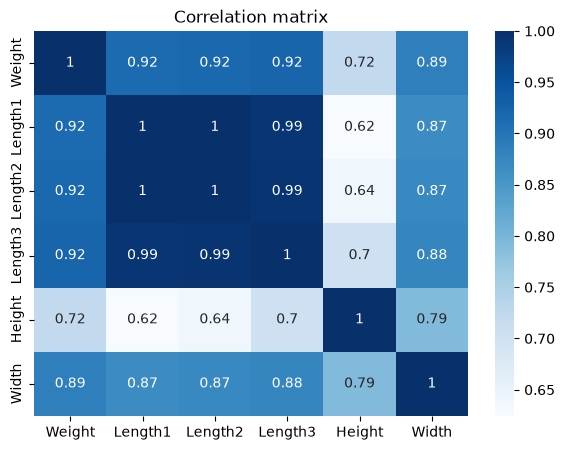

In [26]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap="Blues")
plt.title("Correlation matrix")
plt.show()

📖 `Length1`, `Length2` and `Length3` have correlations above **0.99** with each other. They tell the same story three times.

This is called **multicollinearity**. For a linear model it is a problem: the model cannot decide which of the three deserves the credit, and the coefficients become unstable.

**Decision:** we keep `Length1` and drop the other two.

In [27]:
## feature selection: we drop two highly correlated features
df = df.drop(columns=["Length2", "Length3"])
df.head()

,Species,Weight,Length1,Height,Width
0,Bream,242.0,23.2,11.5200,4.0200
1,Bream,290.0,24.0,12.4800,4.3056
2,Bream,340.0,23.9,12.3778,4.6961
3,Bream,363.0,26.3,12.7300,4.4555
4,Bream,430.0,26.5,12.4440,5.1340


---
## 6 · Model, iteration 1: step by step (10')

The recipe from Tuesday:

1. choose the target `y` and the features `X`
2. turn the text column into numbers (**dummies**)
3. **split** into train and test
4. **standardise** the features
5. **fit** the model on the train set
6. **evaluate** on train and on test

🧑‍💻 Steps 1 and 2.

In [28]:
X = df.drop(columns="Weight")   ## what we feed into the model
y = df["Weight"]                ## what we want to predict

In [29]:
## dummification: one 0/1 column per species
X = pd.get_dummies(X)
X.head()

,Length1,Height,Width,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
0,23.2,11.5200,4.0200,True,False,False,False,False,False,False
1,24.0,12.4800,4.3056,True,False,False,False,False,False,False
2,23.9,12.3778,4.6961,True,False,False,False,False,False,False
3,26.3,12.7300,4.4555,True,False,False,False,False,False,False
4,26.5,12.4440,5.1340,True,False,False,False,False,False,False


🧑‍💻 Step 3: the split. The test set stays hidden until the evaluation.

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(126, 10) (32, 10)


🧑‍💻 Step 4: standardise. For each column: `(value - mean) / std`.

⚠️ The mean and std are learned on the **train** set only (`fit_transform`), then applied to the test set (`transform`). The test set must not influence anything.

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   ## learns mean and std on train, then scales train
X_test_scaled = scaler.transform(X_test)         ## scales test with the mean and std of train

🧑‍💻 Steps 5 and 6: fit and evaluate.

In [33]:
from sklearn.linear_model import LinearRegression

model_1 = LinearRegression()
model_1.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[414.29,-42. , 27.94,..., -4.58, 60.46, 8.04]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,389.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[20.25,14.13,13.27,..., 1.72, 1.15, 0. ]"


In [34]:
from sklearn.metrics import r2_score, mean_absolute_error

predictions_train = model_1.predict(X_train_scaled)
predictions_test = model_1.predict(X_test_scaled)

print("r2 score on the train set:", r2_score(y_train, predictions_train))
print("r2 score on the test set:", r2_score(y_test, predictions_test))
print("mean absolute error on the test set (grams):", mean_absolute_error(y_test, predictions_test))

r2 score on the train set: 0.9248219933923877
r2 score on the test set: 0.9387835896394763
mean absolute error on the test set (grams): 65.55753417667908


📖 R² is about 0.93 on train and 0.94 on test. Train ≈ test, so **no overfitting**. On average the model is wrong by about 65 g.

It looks good. But a score never tells the whole story: let's look at the errors.

🧑‍💻 Residuals = real weight − predicted weight. For a good model they form a cloud around 0 with **no shape**.

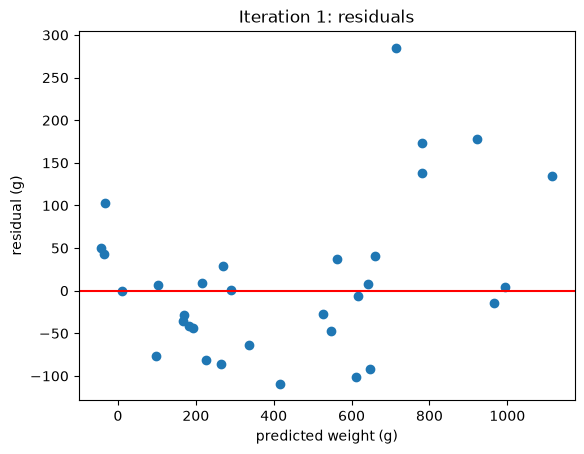

In [35]:
residuals_1 = y_test - predictions_test

plt.scatter(predictions_test, residuals_1)
plt.axhline(0, color="red")
plt.xlabel("predicted weight (g)")
plt.ylabel("residual (g)")
plt.title("Iteration 1: residuals")
plt.show()

In [36]:
## the smallest predictions of the model
print("smallest prediction:", predictions_test.min())
print("number of negative predictions:", (predictions_test < 0).sum())

smallest prediction: -43.10963021661706
number of negative predictions: 3


📖 Two problems hidden behind the good R²:
1. The residuals make a **U shape**: positive for small and big fish, negative in the middle. The model draws a straight line through a curve.
2. Some predictions are **negative**. The model says a small fish weighs less than 0 grams!

Both come from the same cause: the relationship between size and weight is **not a straight line**.

---
## 7 · The log transform (12')

### Why would a logarithm help?
Think about the shape of a fish. Its weight depends on its **volume**, and a volume is

$$\text{weight} \approx c \times \text{length} \times \text{height} \times \text{width}$$

This is a **multiplication**, and a linear model can only **add**. The logarithm turns one into the other:

$$\log(\text{weight}) \approx \log(c) + \log(\text{length}) + \log(\text{height}) + \log(\text{width})$$

After taking logs, the relationship is a sum: exactly what a linear regression can learn.

🧑‍💻 See it: the same scatter plot, before and after the log.

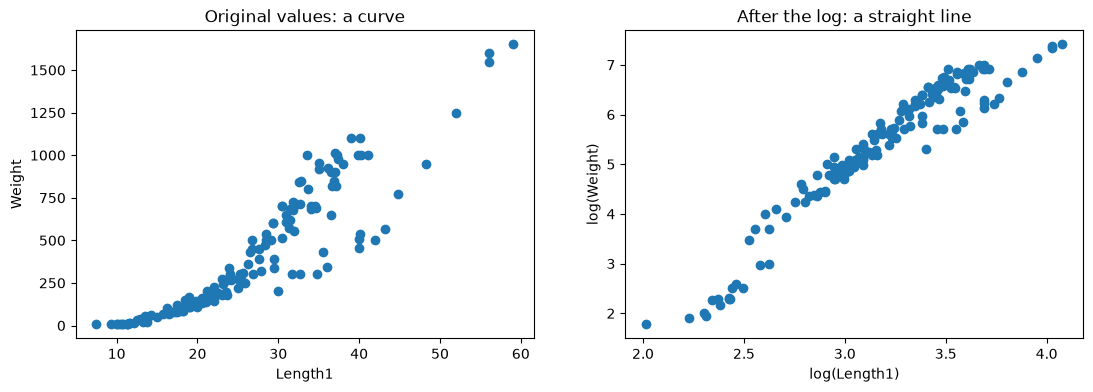

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(df["Length1"], df["Weight"])
axes[0].set_xlabel("Length1")
axes[0].set_ylabel("Weight")
axes[0].set_title("Original values: a curve")

axes[1].scatter(np.log(df["Length1"]), np.log(df["Weight"]))
axes[1].set_xlabel("log(Length1)")
axes[1].set_ylabel("log(Weight)")
axes[1].set_title("After the log: a straight line")

plt.show()

📖 The banana became a straight line. The log did not change the data, it changed the **ruler** we use to look at it.

🧑‍💻 Now the model. Same recipe as iteration 1, with logs on the three size columns and on the target.

In [38]:
## log of the three size columns (the dummies stay as they are)
X_log = X.copy()
X_log["Length1"] = np.log(X_log["Length1"])
X_log["Height"] = np.log(X_log["Height"])
X_log["Width"] = np.log(X_log["Width"])

## log of the target
y_log = np.log(y)

X_log.head()

,Length1,Height,Width,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
0,3.144152,2.444085,1.391282,True,False,False,False,False,False,False
1,3.178054,2.524127,1.459917,True,False,False,False,False,False,False
2,3.173878,2.515905,1.546732,True,False,False,False,False,False,False
3,3.269569,2.543961,1.494139,True,False,False,False,False,False,False
4,3.277145,2.521239,1.635885,True,False,False,False,False,False,False


In [39]:
## same split as before (same random_state = same fish in train and test)
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_log, y_log, test_size=0.2, random_state=42)

In [41]:
scaler_log = StandardScaler()
X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

model_2 = LinearRegression()
model_2.fit(X_train_log_scaled, y_train_log)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.63, 0.35, 0.34,..., 0. ,-0.04, 0.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.391
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[21.17,13.64,12.83,..., 1.22, 0.73, 0. ]"


🧑‍💻 The model now predicts **log(weight)**. Nobody buys fish in "log grams", so we go back to grams with the opposite of the log: `np.exp`.

In [42]:
predictions_log = model_2.predict(X_test_log_scaled)   ## predictions in log grams
predictions_grams = np.exp(predictions_log)            ## back to grams

predictions_grams[:5]

array([276.30834556, 137.09308055, 471.78845242,  23.34785342,
       133.78720736])

🧑‍💻 Compare both models **in grams**, on the same test fish.

In [43]:
print("ITERATION 1 (original values)")
print("r2 score on the test set:", r2_score(y_test, predictions_test))
print("mean absolute error (grams):", mean_absolute_error(y_test, predictions_test))
print("negative predictions:", (predictions_test < 0).sum())

print()
print("ITERATION 2 (log transform)")
print("r2 score on the test set:", r2_score(y_test, predictions_grams))
print("mean absolute error (grams):", mean_absolute_error(y_test, predictions_grams))
print("negative predictions:", (predictions_grams < 0).sum())

ITERATION 1 (original values)
r2 score on the test set: 0.9387835896394763
mean absolute error (grams): 65.55753417667908
negative predictions: 3

ITERATION 2 (log transform)
r2 score on the test set: 0.98421763711819
mean absolute error (grams): 29.392838720381082
negative predictions: 0


📖 **The benefit of the log transform, in numbers**
- R² on the test set goes from about **0.94 to 0.98**.
- The average error is **cut in half**: from about 65 g to about 30 g.
- **No negative prediction** any more: `np.exp` of any number is always positive.

Same data, same algorithm. We only changed how we present the data to the model.

🧑‍💻 And the residuals?

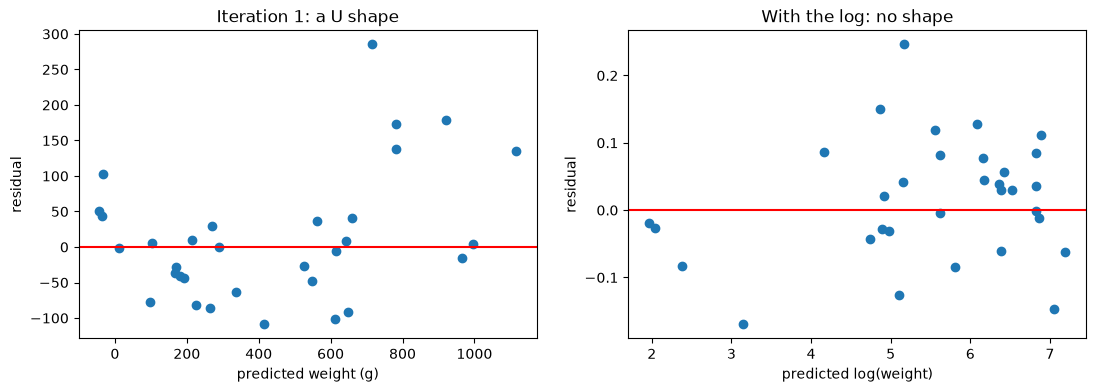

In [44]:
residuals_2 = y_test_log - predictions_log

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(predictions_test, residuals_1)
axes[0].axhline(0, color="red")
axes[0].set_title("Iteration 1: a U shape")
axes[0].set_xlabel("predicted weight (g)")
axes[0].set_ylabel("residual")

axes[1].scatter(predictions_log, residuals_2)
axes[1].axhline(0, color="red")
axes[1].set_title("With the log: no shape")
axes[1].set_xlabel("predicted log(weight)")
axes[1].set_ylabel("residual")

plt.show()

📖 The U shape is gone: the residuals are now a cloud around 0. This is what a healthy linear model looks like.

**When to think of a log transform**
- the target or a feature is **right-skewed** (money, weights, counts, populations)
- the scatter plot is **curved** and opens like a fan
- the quantities **multiply** each other
- the values must be **strictly positive** (log of 0 does not exist: one more reason we removed the 0 g fish)

---
## 8 · The statistics of the model (4')

`scikit-learn` gives us the coefficients. `statsmodels` gives us the coefficients **with their confidence intervals**: the same idea as part 4, applied to the model.

To read them easily we use only the three size columns, in logs, without scaling.

In [45]:
import statsmodels.api as sm

size_columns = ["Length1", "Height", "Width"]

X_train_constant = sm.add_constant(X_train_log[size_columns])   ## adds the intercept b0
ols_model = sm.OLS(y_train_log, X_train_constant)
results = ols_model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                 Weight   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                     7395.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          9.10e-138
Time:                        18:21:18   Log-Likelihood:                 117.09
No. Observations:                 126   AIC:                            -226.2
Df Residuals:                     122   BIC:                            -214.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.7241      0.124    -13.903      0.0

In [46]:
## the 95% confidence intervals of the coefficients
results.conf_int()

,0,1
const,-1.969611,-1.478622
Length1,1.308572,1.528179
Height,0.534379,0.681139
Width,0.837435,1.102671


📖 **How to read the table**
- `coef`: the coefficient. In a log–log model it reads in **percent**: +1% of length goes with about +1.4% of weight.
- `[0.025  0.975]`: the 95% confidence interval of the coefficient. If it does **not contain 0**, the feature has a real effect.
- `P>|t|`: the p-value. Below 0.05 means the same thing: the effect is unlikely to be chance.

**A nice check:** add the three coefficients. You get about **3**. Double every dimension of a fish and its weight is multiplied by 2³ = 8: the model has found the formula of a **volume** by itself.

In [47]:
results.params[size_columns].sum()

np.float64(2.9961874758141898)

---
## 9 · Model, iteration 2: the `Pipeline` (8')

Look back at what we did by hand: log, dummies, split, scaler on train, scaler on test, fit, predict. Many steps, many variables (`X_train_log_scaled`...), many chances to make a mistake, like scaling the test set with its own mean.

A **`Pipeline`** puts all the steps in **one object**:
- `pipeline.fit(X_train, y_train)` → every step learns from the **train** set only
- `pipeline.predict(X_test)` → the same steps are applied, in the same order

Same model, same results. Cleaner code, and no data leakage by construction.

🧑‍💻 We start again from the raw columns.

In [48]:
numeric_features = ["Length1", "Height", "Width"]
categorical_features = ["Species"]

X = df[numeric_features + categorical_features]   ## raw columns: no log, no dummies
y_log = np.log(df["Weight"])

X_train, X_test, y_train_log, y_test_log = train_test_split(X, y_log, test_size=0.2, random_state=42)
X_train.head()

,Length1,Height,Width,Species
138,43.2,7.7920,4.8700,Pike
56,24.1,8.1454,4.2485,Whitefish
127,41.1,12.4888,7.5958,Perch
85,19.3,6.3840,3.5340,Perch
155,11.7,2.4300,1.2690,Smelt


🧑‍💻 The preprocessing. Each kind of column gets its own treatment:
- numeric columns: **log**, then **scale**
- text column: **dummies** (in a pipeline this is called `OneHotEncoder`)

`ColumnTransformer` sends each column to the right treatment.

In [49]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer

## numeric columns: first the log, then the scaler
numeric_steps = make_pipeline(FunctionTransformer(np.log), StandardScaler())

## the text column: dummies
categorical_steps = OneHotEncoder(handle_unknown="ignore")

preprocessing = ColumnTransformer([
    ("numeric", numeric_steps, numeric_features),
    ("categorical", categorical_steps, categorical_features),
])

🧑‍💻 The full pipeline: preprocessing, then the model.

In [50]:
pipeline = make_pipeline(preprocessing, LinearRegression())
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thresho

In [51]:
pipeline.fit(X_train, y_train_log)

predictions_pipeline = np.exp(pipeline.predict(X_test))   ## back to grams

print("r2 score on the test set:", r2_score(np.exp(y_test_log), predictions_pipeline))
print("mean absolute error (grams):", mean_absolute_error(np.exp(y_test_log), predictions_pipeline))

r2 score on the test set: 0.9842176371181899
mean absolute error (grams): 29.39283872038118


📖 Exactly the same score as in part 7: it is the **same model**, written in a cleaner way.

Now the real benefit: predicting a **new fish** from its raw measurements takes one line.

In [52]:
new_fish = pd.DataFrame({"Length1": [30], "Height": [12], "Width": [5], "Species": ["Bream"]})

print("predicted weight (g):", np.exp(pipeline.predict(new_fish)))

predicted weight (g): [467.01012908]


🧑‍💻 Bonus: **cross-validation**. The data is split 5 times, and each time the whole pipeline is trained again on the train part only. This is only safe because the scaler lives **inside** the pipeline.

Our file is sorted by species, so we ask for the folds to be **shuffled** first.

In [53]:
from sklearn.model_selection import cross_val_score, KFold

folds = KFold(n_splits=5, shuffle=True, random_state=42)   ## 5 shuffled folds
scores = cross_val_score(pipeline, X, y_log, cv=folds)

print("r2 on the 5 folds:", scores)
print("average:", scores.mean())

r2 on the 5 folds: [0.99606593 0.99422501 0.99695323 0.99003239 0.99670981]
average: 0.9947972736443796


---
## 10 · Correlated features: unstable coefficients (7')

☕ **Second half.** So far our best model is the log model: test R² 0.98 with a handful of features.

In part 5 we **dropped** `Length2` and `Length3` because they repeat `Length1`. What would have happened if we had kept them? This is the problem that **regularisation** was invented to solve.

🧑‍💻 We start again from the file, with **all** the columns, in grams (no log).

In [55]:
fish = pd.read_csv("../data/Fish.csv")
fish = fish[fish["Weight"] > 0]

X = pd.get_dummies(fish.drop(columns="Weight"))   ## the three lengths are back
y = fish["Weight"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X.columns

Index(['Length1', 'Length2', 'Length3', 'Height', 'Width', 'Species_Bream',
       'Species_Parkki', 'Species_Perch', 'Species_Pike', 'Species_Roach',
       'Species_Smelt', 'Species_Whitefish'],
      dtype='str')

🧑‍💻 We are going to train many models. To avoid repeating the same lines, we write **one function** that does the three steps: transform the features, fit the model, print the scores.

In [56]:
def model_inplace(transformer, model, X_train, X_test, y_train, y_test):
    x_train = transformer.fit_transform(X_train)   ## learn the transformation on train
    x_test = transformer.transform(X_test)         ## apply it to test
    model.fit(x_train, y_train)
    print("r2 score on train set", model.score(x_train, y_train))
    print("r2 score on test set", model.score(x_test, y_test))

In [57]:
baseline_model = LinearRegression()
scaler1 = StandardScaler()

model_inplace(scaler1, baseline_model, X_train, X_test, y_train, y_test)

r2 score on train set 0.9289937650649452
r2 score on test set 0.9497220657678432


📖 The score is fine, about the same as iteration 1. Now look at the **coefficients** of the three lengths.

In [58]:
coefficients = pd.DataFrame({"linear": baseline_model.coef_}, index=X.columns)
coefficients

,linear
Length1,-626.836191
Length2,699.599870
Length3,373.729130
Height,-55.024271
Width,24.698391
Species_Bream,-4.887391
Species_Parkki,31.254353
Species_Perch,12.667413
Species_Pike,-113.978889
Species_Roach,-1.112691


📖 `Length1` gets about **−630** and `Length2` about **+700**. The model says: "a longer fish is much lighter… and much heavier". The two almost cancel out.

The three lengths carry the same information, so the model cannot decide how to share the credit. It finds huge coefficients with opposite signs that happen to fit the training fish. This is **multicollinearity** in action:
- the **predictions** are still fine
- the **coefficients** mean nothing, and they would change completely with a few different fish

Dropping columns by hand (part 5) is one solution. Regularisation is the automatic one. First, let's make the problem worse.

---
## 11 · Polynomial features: more power… and overfitting (10')

In part 7 we fixed the curve with a **log**, because we understood the data (a weight is a volume).

There is another way, which needs no understanding: give the model new columns made of **squares and products** of the existing ones (`Length1²`, `Length1 × Height`, …) and let it build the curve itself. This is what `PolynomialFeatures` does.

We chain it with the scaler in a small pipeline: scale → create the polynomial columns → scale again.

In [59]:
from sklearn.preprocessing import PolynomialFeatures

poly2 = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), StandardScaler())
poly3 = make_pipeline(StandardScaler(), PolynomialFeatures(degree=3, include_bias=False), StandardScaler())

In [60]:
## dimensionality augmentation: how many columns do we get?
print("training fish:", X_train.shape[0])
print("original features:", X_train.shape[1])
print("degree 2:", poly2.fit_transform(X_train).shape[1])
print("degree 3:", poly3.fit_transform(X_train).shape[1])

training fish: 126
original features: 12
degree 2: 90
degree 3: 454


📖 From 12 columns to 90, then to 454. And we have 126 fish to learn from: with degree 3, **more features than fish**.

In [61]:
model_inplace(poly2, baseline_model, X_train, X_test, y_train, y_test)

r2 score on train set 0.9914950062641523
r2 score on test set 0.964519419353949


In [62]:
model_inplace(poly3, baseline_model, X_train, X_test, y_train, y_test)

r2 score on train set 0.9990246368820864
r2 score on test set -8.580964268257542


📖 **Degree 2:** train and test both go up. The model built the curve by itself, without any log.

**Degree 3:** the train score is almost a perfect 1… and the test score **collapses** to a negative number. A negative R² means the model is worse than answering "the average weight" for every fish.

With 454 features for 126 fish, the model has enough freedom to learn every training fish **by heart**, noise included. This is **overfitting**.

🧑‍💻 What does a collapsed model predict? Real fish weigh between 6 g and 1,650 g.

In [63]:
x_train = poly3.fit_transform(X_train)
x_test = poly3.transform(X_test)
baseline_model.fit(x_train, y_train)
predictions = baseline_model.predict(x_test)

print("smallest prediction:", predictions.min())
print("biggest prediction:", predictions.max())

smallest prediction: -3642.6146951848195
biggest prediction: 1621.6705938557723


📖 A fish of minus several kilos. On the training fish the model is perfect; on a fish it has never seen, it can say anything.

🧑‍💻 The picture to remember: train against test for the three models.

In [64]:
names = ["degree 1", "degree 2", "degree 3"]
transformers = [StandardScaler(), poly2, poly3]

train_scores = []
test_scores = []

for transformer in transformers:
    x_train = transformer.fit_transform(X_train)
    x_test = transformer.transform(X_test)
    model = LinearRegression()
    model.fit(x_train, y_train)
    train_scores.append(model.score(x_train, y_train))
    test_scores.append(model.score(x_test, y_test))

scores = pd.DataFrame({"train": train_scores, "test": test_scores}, index=names)
scores

,train,test
degree 1,0.928994,0.949722
degree 2,0.991495,0.964519
degree 3,0.999025,-8.580964


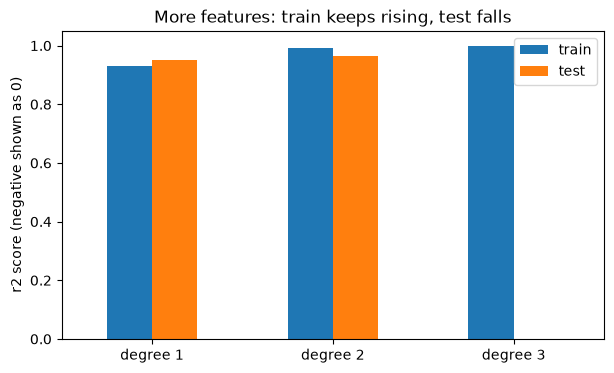

In [65]:
## a negative score is shown as 0 so that the chart stays readable
scores.clip(lower=0).plot(kind="bar", figsize=(7, 4), rot=0)
plt.ylabel("r2 score (negative shown as 0)")
plt.title("More features: train keeps rising, test falls")
plt.ylim(0, 1.05)
plt.show()

📖 **The gap between the two bars is the signature of overfitting.** The train bar alone would have told us degree 3 is the best model. It is the worst.

---
## 12 · Ridge and Lasso (10')

Both problems we just saw, the lengths with −630 and +700 and the collapsed degree 3, have the same symptom: **huge coefficients**.

Regularisation adds a **penalty** for big coefficients to what the model minimises:

- **Ridge (L2):** errors + `alpha` × (sum of the **squared** coefficients)
- **Lasso (L1):** errors + `alpha` × (sum of the **absolute** coefficients)

`alpha` is the strength of the penalty: `alpha = 0` is a plain linear regression; a very large `alpha` pushes every coefficient towards 0.

⚠️ The penalty looks at the **size** of the coefficients, so the features must be on the same scale: **always scale before regularising**.

In [66]:
from sklearn.linear_model import Ridge, Lasso

## regularisations
ridge = Ridge(alpha=10)                    ## L2 regulariser
lasso = Lasso(alpha=1, max_iter=200000)    ## L1 regulariser

🧑‍💻 The same 454 features of degree 3 that collapsed, now with a penalty.

In [67]:
model_inplace(poly3, ridge, X_train, X_test, y_train, y_test)

r2 score on train set 0.9911583260119825
r2 score on test set 0.9760762619659219


In [68]:
model_inplace(poly3, lasso, X_train, X_test, y_train, y_test)

r2 score on train set 0.9906279089840397
r2 score on test set 0.9790784661287966


📖 From a negative score back to about **0.98** on the test set. The train score went down a little: that is the price, and it is a good deal.

We kept the flexible model and removed its freedom to do silly things.

In [69]:
## how many of the 454 coefficients did each model keep?
print("coefficients not equal to 0 with Ridge:", (ridge.coef_ != 0).sum())
print("coefficients not equal to 0 with Lasso:", (lasso.coef_ != 0).sum())

coefficients not equal to 0 with Ridge: 454
coefficients not equal to 0 with Lasso: 27


📖 The big difference between the two:
- **Ridge** keeps all 454 features, with small coefficients.
- **Lasso** sets most coefficients to **exactly 0**: it keeps fewer than 30 features out of 454. Lasso does **feature selection** for us.

🧑‍💻 **See it.** Back to the 12 original features and to the three lengths of part 10: what do Ridge and Lasso do with them?

In [70]:
x_train = scaler1.fit_transform(X_train)
x_test = scaler1.transform(X_test)

linear = LinearRegression().fit(x_train, y_train)
ridge = Ridge(alpha=10).fit(x_train, y_train)
lasso = Lasso(alpha=5, max_iter=200000).fit(x_train, y_train)

coefficients = pd.DataFrame({"linear": linear.coef_, "ridge": ridge.coef_, "lasso": lasso.coef_}, index=X.columns)
coefficients.round(0)

,linear,ridge,lasso
Length1,-627.0,97.0,0.0
Length2,700.0,99.0,255.0
Length3,374.0,97.0,98.0
Height,-55.0,37.0,0.0
Width,25.0,64.0,41.0
Species_Bream,-5.0,-13.0,-0.0
Species_Parkki,31.0,8.0,10.0
Species_Perch,13.0,3.0,-0.0
Species_Pike,-114.0,-45.0,-75.0
Species_Roach,-1.0,-7.0,-4.0


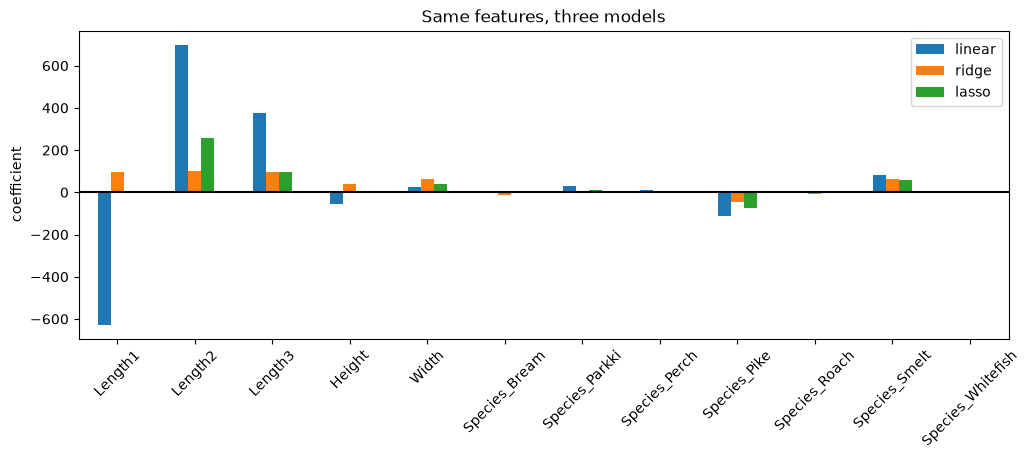

In [71]:
coefficients.plot(kind="bar", figsize=(12, 4), rot=45)
plt.axhline(0, color="black")
plt.ylabel("coefficient")
plt.title("Same features, three models")
plt.show()

📖 Look at the three lengths:
- **Linear:** about −630, +700, +370. Huge, opposite signs, meaningless.
- **Ridge:** about +97, +99, +97. It **shares the credit equally** between the three lengths, which is exactly right: they measure the same thing.
- **Lasso:** it sets `Length1` to **0** and keeps the other two. It does by itself what we did by hand in part 5: drop a redundant column.

Ridge is the good choice when the correlated features all matter a little. Lasso is the good choice when you want a short list of features.

---
## 13 · The effect of alpha and `GridSearchCV` (10')

How do the coefficients change when we turn the `alpha` knob? We fit a Lasso for many values of alpha and store the coefficients each time.

In [72]:
alphas = np.logspace(-1, 2.7, 50)   ## 50 values from 0.1 to about 500

lasso_coefficients = []
lasso_train_scores = []
lasso_test_scores = []

for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=200000)
    model.fit(x_train, y_train)
    lasso_coefficients.append(model.coef_)
    lasso_train_scores.append(model.score(x_train, y_train))
    lasso_test_scores.append(model.score(x_test, y_test))

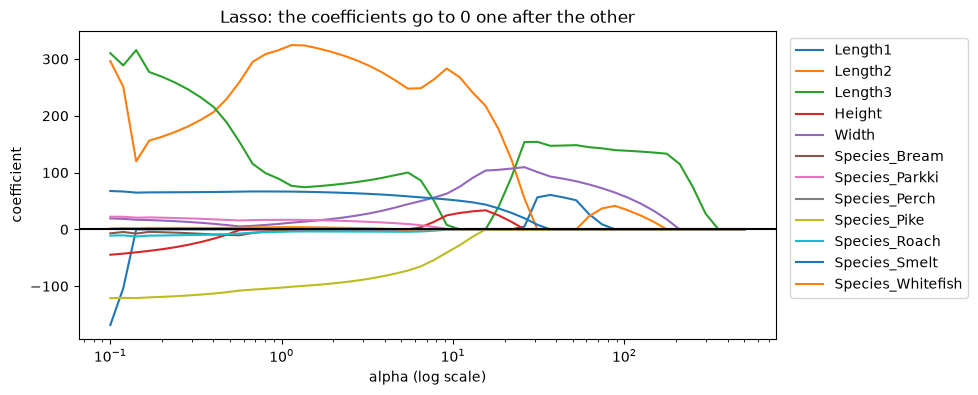

In [73]:
plt.figure(figsize=(9, 4))
plt.plot(alphas, lasso_coefficients)
plt.xscale("log")
plt.axhline(0, color="black")
plt.xlabel("alpha (log scale)")
plt.ylabel("coefficient")
plt.title("Lasso: the coefficients go to 0 one after the other")
plt.legend(X.columns, bbox_to_anchor=(1.01, 1))
plt.show()

📖 Read it from left to right, like turning a knob:
- On the left (small alpha): almost a plain linear regression, with the big opposite coefficients of the lengths.
- Moving right: the lines reach 0 **one after the other**. The features the model needs least disappear first.
- On the far right: everything is 0. The model predicts the average weight for every fish.

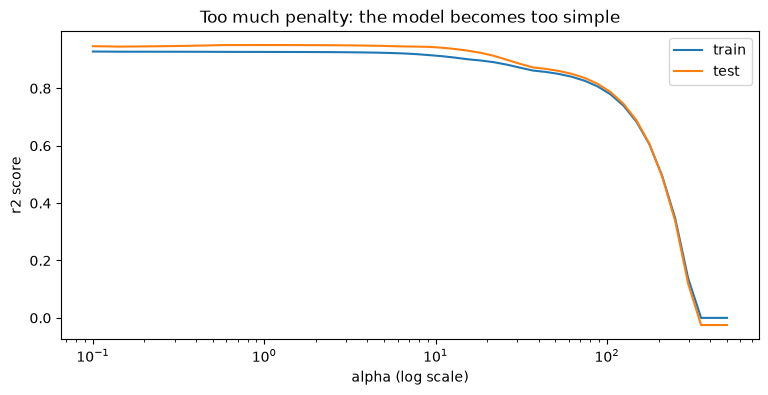

In [74]:
plt.figure(figsize=(9, 4))
plt.plot(alphas, lasso_train_scores, label="train")
plt.plot(alphas, lasso_test_scores, label="test")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("r2 score")
plt.title("Too much penalty: the model becomes too simple")
plt.legend()
plt.show()

📖 With too much penalty (right side) both scores fall: the model is too simple, it **underfits**. Too little penalty and we are back to overfitting. The best alpha is in between.

How do we find it **without looking at the test set**?

### `GridSearchCV`
`alpha` is a **hyperparameter**: a setting we choose, not something the model learns.

`GridSearchCV` is a `for` loop over the values we give it. For each one it does a **cross-validation** inside the train set (here 5 folds) and keeps the value with the best average score. The test set is never used.

We search on the 454 features of degree 3, where the penalty really matters.

In [75]:
## hyperparameter tuning: choosing the best parameters of the model
from sklearn.model_selection import GridSearchCV

x_train = poly3.fit_transform(X_train)
x_test = poly3.transform(X_test)

params = {"alpha": [0.1, 0.5, 1, 5, 10, 50]}

grid = GridSearchCV(Lasso(max_iter=200000), param_grid=params, cv=5)
grid.fit(x_train, y_train)

print("best alpha", grid.best_params_)

best alpha {'alpha': 10}


In [76]:
best_model = grid.best_estimator_

print("score on train set", best_model.score(x_train, y_train))
print("score on test set", best_model.score(x_test, y_test))
print("features kept by Lasso:", (best_model.coef_ != 0).sum(), "out of", len(best_model.coef_))

score on train set 0.9800038192666677
score on test set 0.9724714130941128
features kept by Lasso: 11 out of 454


📖 `GridSearchCV` chose the alpha by itself, using only the training fish, and the model it returns scores about 0.97 on the test set with only a few of the 454 features.

**Now compare the two roads we took today:**

| Road | Features | Test R² |
|---|---|---|
| Understanding the data: **log transform** (part 7) | 10 | **0.98** |
| Brute force: degree 3 polynomials, no penalty (part 11) | 454 | collapses |
| Brute force + **Lasso** (this part) | about 10 kept out of 454 | 0.97 |

Regularisation saved the brute-force model. But the simple model built on an understanding of the data (a weight is a volume) is just as good, and far easier to explain. **Regularisation is a safety net, not a replacement for knowing your data.**

---
## 14 · Recap (3')

| Step | What we learned |
|---|---|
| Cleaning | `describe()` reveals impossible values (0 g). Remove what is wrong, keep what is rare but real. |
| EDA | The target is right-skewed, the relationship with length is curved, the three lengths are redundant. |
| Confidence interval | mean ± t × std/√n. Few data → wide interval. It also exists for model coefficients. |
| Iteration 1 | R² 0.94 looked fine, but the residuals had a U shape and some predictions were negative. |
| Log transform | Turns a multiplication into a sum. Test R² 0.94 → 0.98, error cut in half, no negative prediction. |
| Pipeline | All the steps in one object: less code, no leakage, new predictions and cross-validation in one line. |
| Multicollinearity | Redundant features → huge coefficients with opposite signs. Predictions fine, coefficients meaningless. |
| Overfitting | Many features, few rows: train score up, test score down. Look at the **gap**. |
| Ridge (L2) | Shrinks all the coefficients and shares the credit between correlated features. |
| Lasso (L1) | Sets some coefficients to exactly 0: automatic **feature selection**. |
| alpha | The strength of the penalty. Too small: overfitting. Too big: underfitting. Chosen with `GridSearchCV`. |

**The habit to keep:** model → look at the residuals and at the train/test gap → understand what is wrong → improve → repeat.

➡️ **Homework:** you apply all of this, step by step, to a new dataset.